# Detect songs with the best model and look at each one

This notebook runs the best Experiment 3 setup on the 10-hour recording, lists every song it detects, and shows the spectrogram of each song.

- **Recording:** `SOCAL_H_76_230426_193500_df100.x.x.wav` (2 kHz, 10 h, starting 2023-04-26 19:35:00 UTC).
- **Input `S2_N1_X2_20s`:**
  - a 0.128 s / 0.025 s spectrogram in 50 semitone bands;
  - a rolling-median noise floor;
  - a 20 s phrase window every 2 s, described by its 2D-Fourier rhythm-and-shape pattern;
  - 40 PCA components.
- **Model M1:** a theme HMM. Themes run T1 → … → T6, and T6 → T1 is a song boundary. Sessions end only after more than 60 s of background.

How it works and how well: [`../best_combination.md`](../best_combination.md).

**What a "song" is here:** the stretch between two song boundaries (T6 → T1) inside one session.
- A song is **complete** when it starts at T1 and ends in T6.
- It is **partial** when it is cut by a session edge or by the train/test split at 5 h. The model decodes each half separately.

**Known weaknesses to keep in mind:**
- the model tends to make songs too short (median about 6 minutes, while Payne & McVay give 7–30);
- it confuses T2, T3 and T5;
- it rarely finds the short themes T1 and T4.

The spectrograms below let you judge each detection by eye.

In [1]:
import sys
from pathlib import Path

# make the repository importable (this notebook lives in analysis/song_exp3/notebooks/)
root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]  # keeps the notebook small with ~80 spectrograms
%config InlineBackend.print_figure_kwargs = {"pil_kwargs": {"quality": 70}, "bbox_inches": "tight"}
plt.rcParams["figure.dpi"] = 72

from analysis.song_exp3 import detect

## 1. Load the model

The fitted model is saved in `work/models/M1/model.pkl`. If it is missing, this cell builds the input from the wav and trains M1 once on the first 5 hours, which takes about a minute.

In [2]:
model = detect.load_model()
print("model loaded:", detect.MODEL_PATH.relative_to(root))

model loaded: analysis\song_exp3\work\models\M1\model.pkl


## 2. Run it on the recording and list the songs

Times are given in minutes from the start of the recording and as UTC clock time. The `T1 (s)` … `T6 (s)` columns are the seconds of each theme inside the song.

In [3]:
songs, decoded = detect.detect_songs(model)
complete = [s for s in songs if s.complete]
print(f"{len(songs)} songs detected ({len(complete)} complete, {len(songs) - len(complete)} partial)")
table = detect.song_table(songs)
table

79 songs detected (62 complete, 17 partial)


,start (min),end (min),length (min),start (UTC),end (UTC),complete,T1 (s),T2 (s),T3 (s),T4 (s),T5 (s),T6 (s)
song,,,,,,,,,,,,
1,1.88,15.78,13.90,19:36:53,19:50:47,False,418,344,72,0,0,0
2,22.88,30.90,8.02,19:57:53,20:05:54,False,1,324,46,62,30,18
3,30.90,33.93,3.03,20:05:54,20:08:56,True,2,114,60,2,2,2
4,33.93,50.10,16.17,20:08:56,20:25:06,True,2,598,204,32,96,38
5,50.10,56.40,6.30,20:25:06,20:31:24,True,2,126,24,12,160,54
...,...,...,...,...,...,...,...,...,...,...,...,...
75,537.60,541.20,3.60,04:32:36,04:36:12,True,2,126,20,2,2,64
76,541.20,547.77,6.57,04:36:12,04:42:46,True,20,120,248,2,2,2
77,547.77,561.37,13.60,04:42:46,04:56:22,True,2,508,292,2,10,2


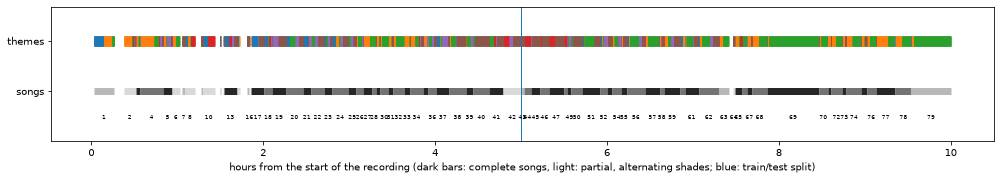

In [4]:
fig = detect.plot_overview(songs, decoded)

## 3. The spectrogram of every detected song

Each plot shows one song, with 15 s of context on each side. The coloured strip is the theme the model assigned to each second, and the cyan lines are the song boundaries it found. Each image is also saved to `work/song_spectrograms/`.

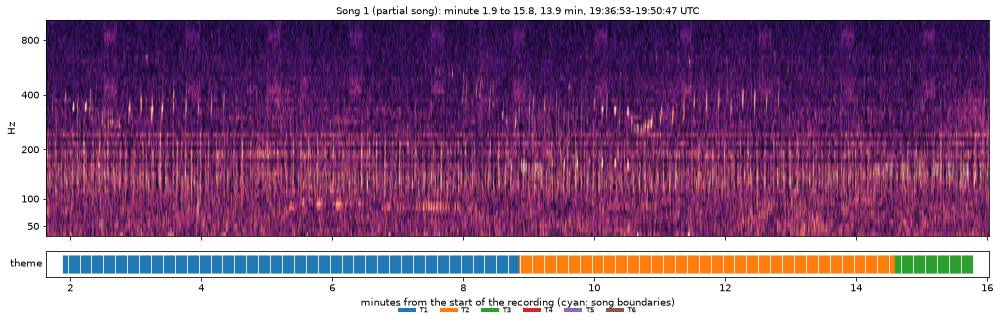

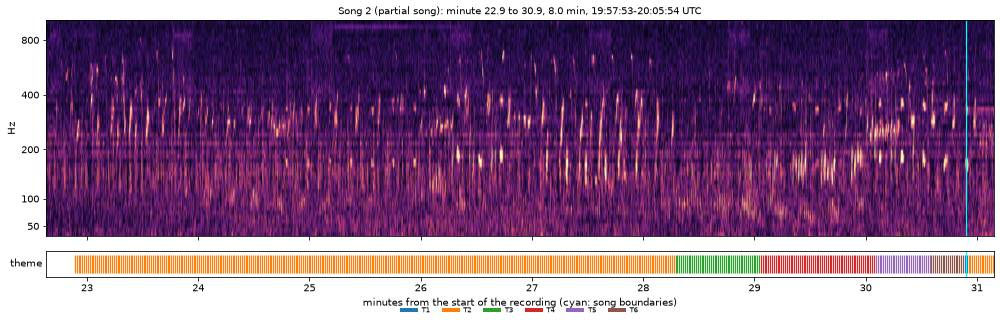

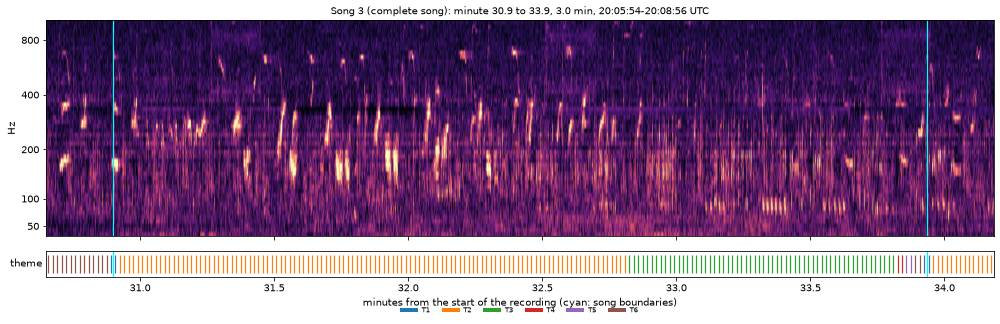

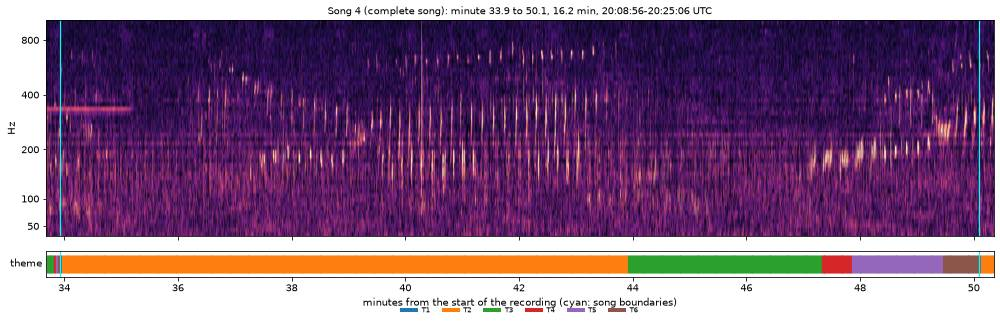

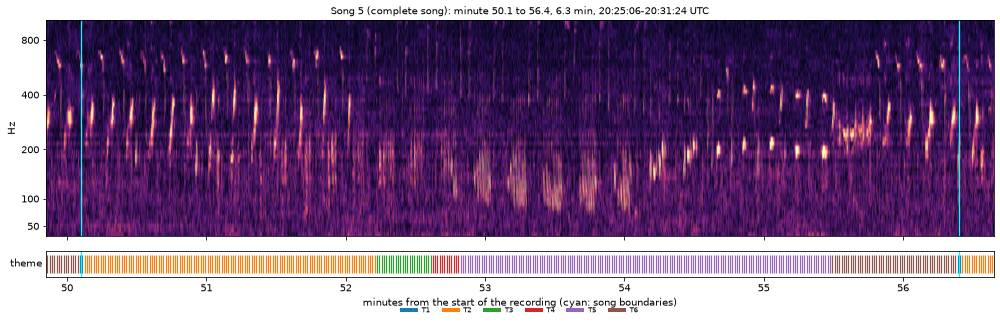

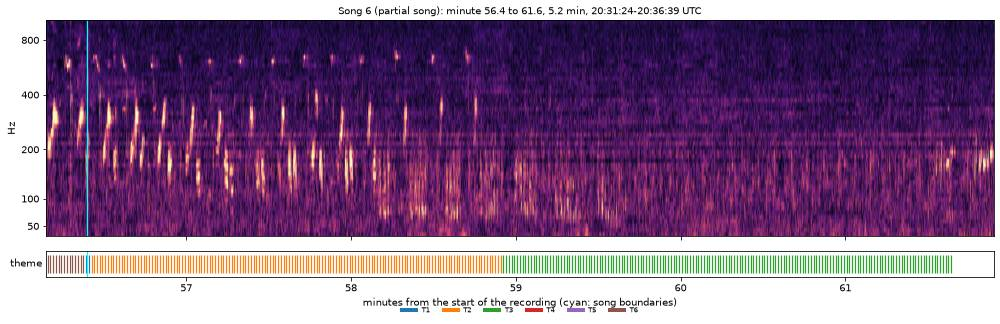

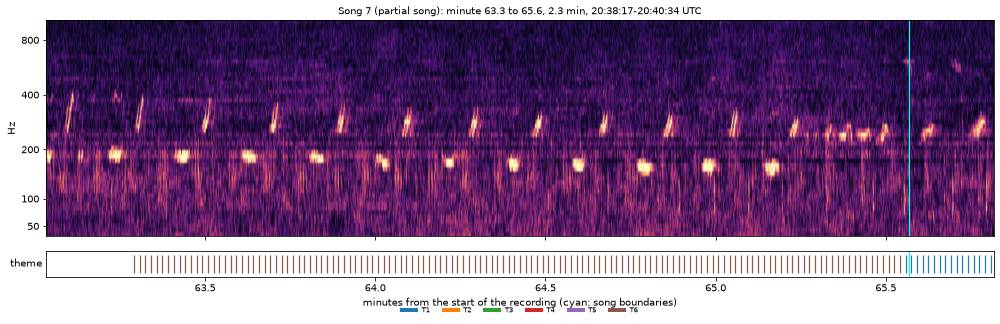

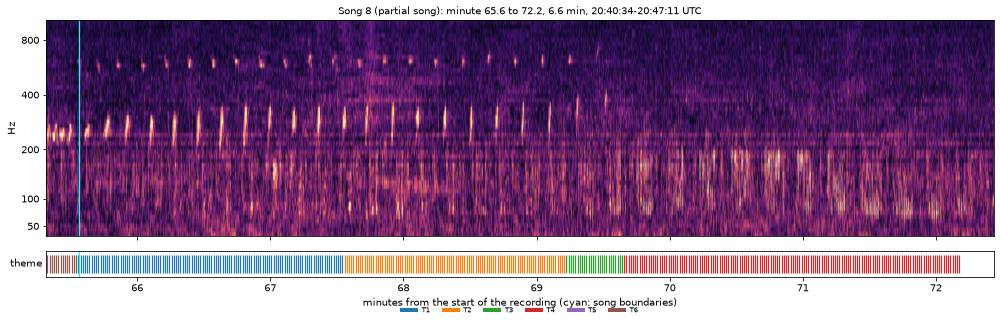

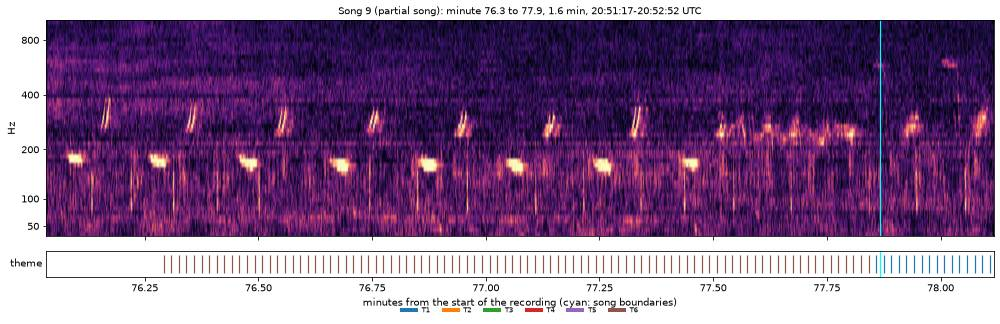

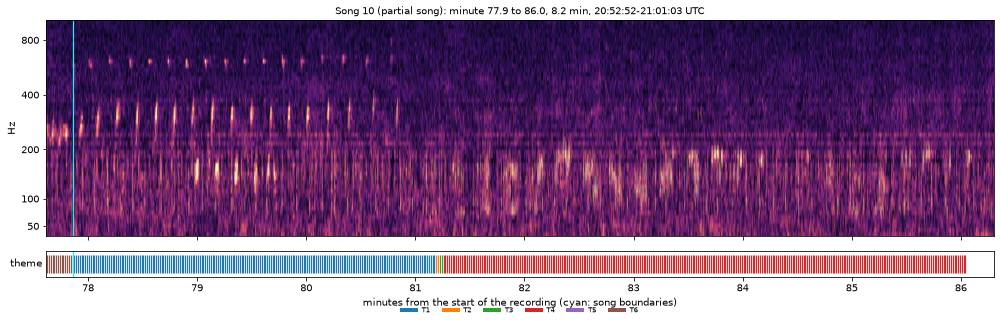

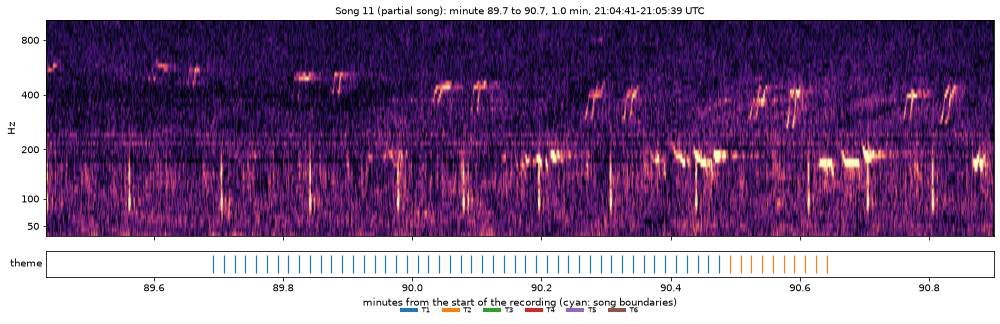

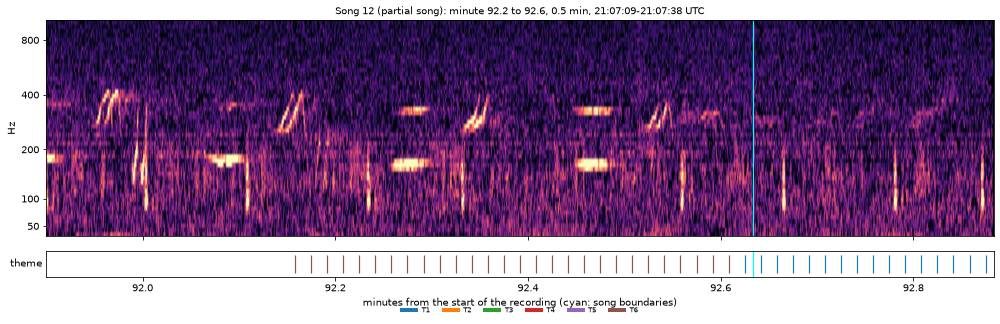

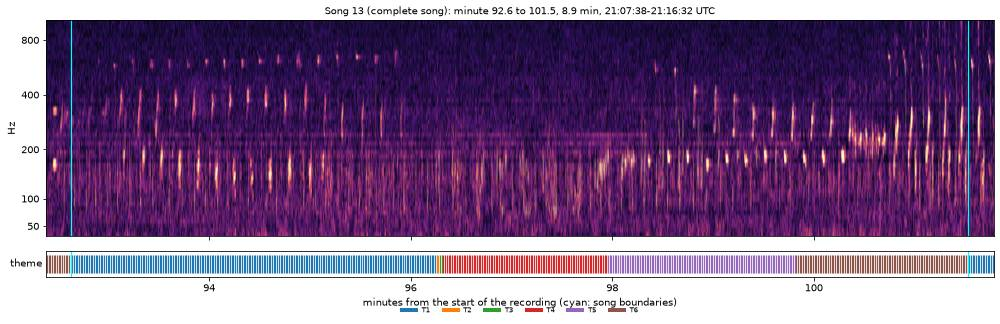

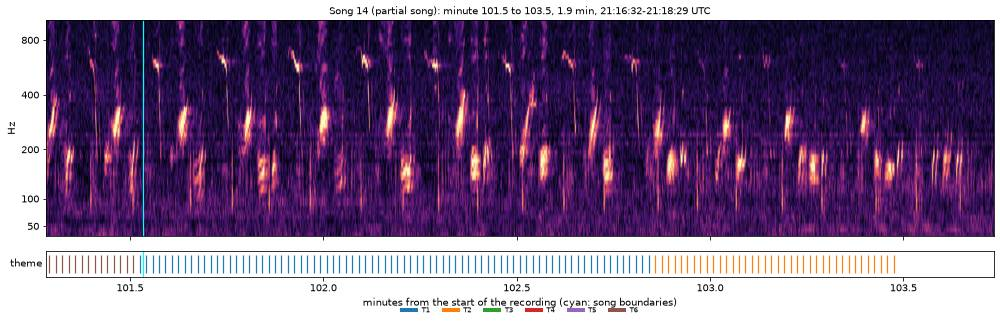

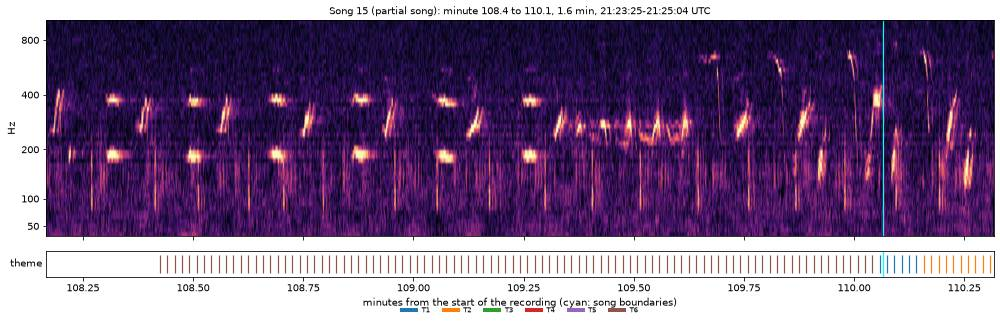

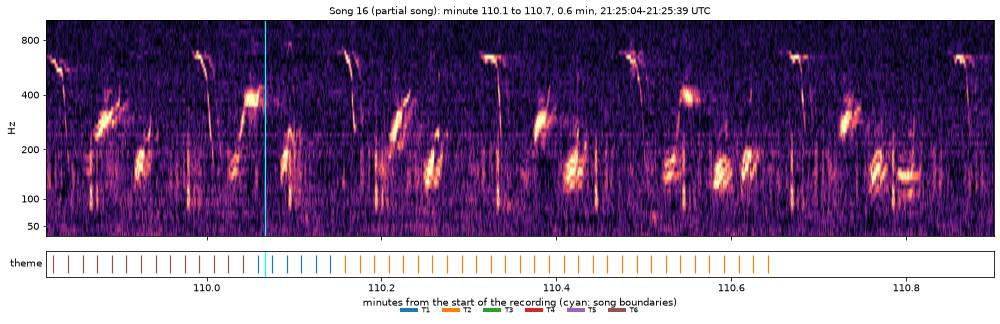

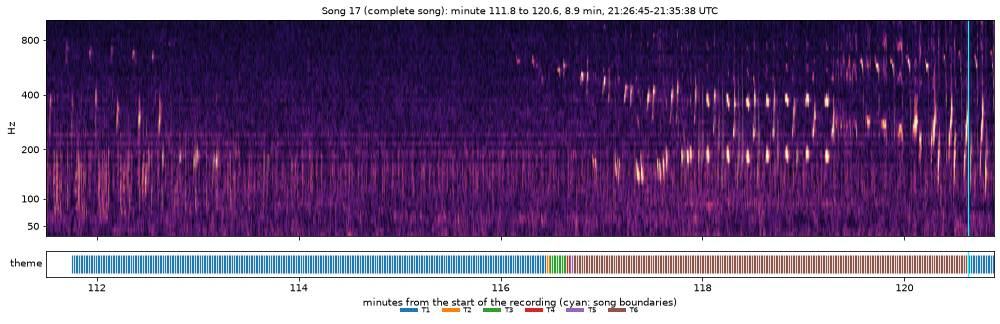

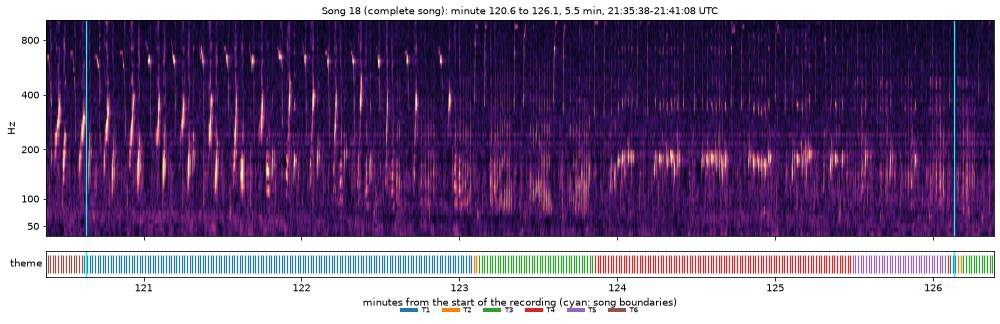

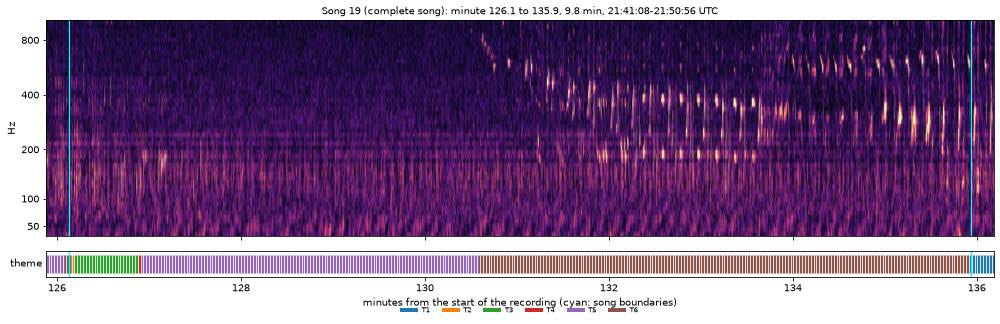

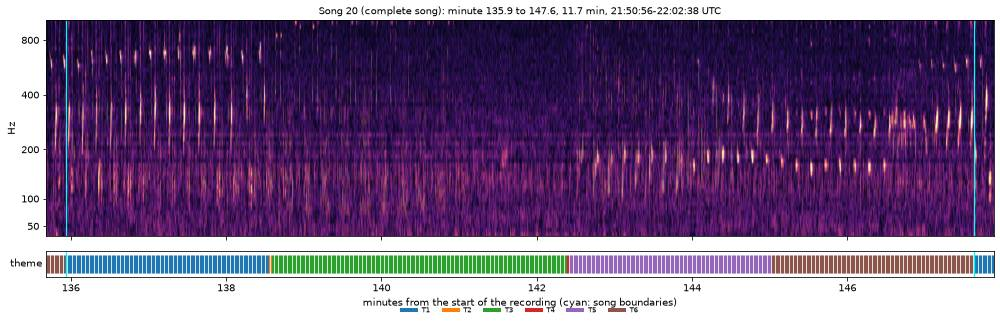

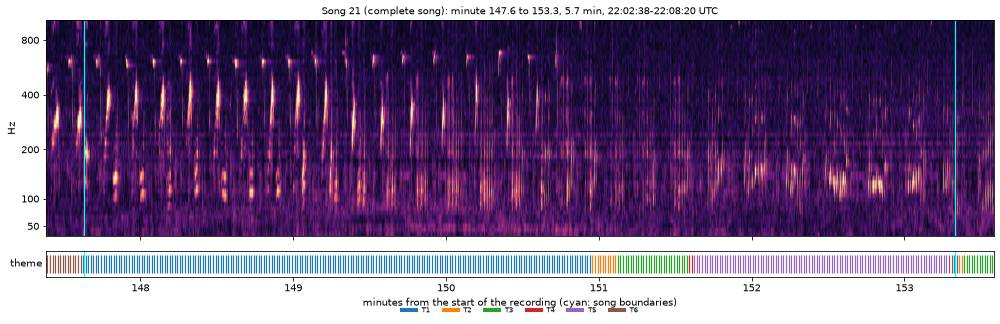

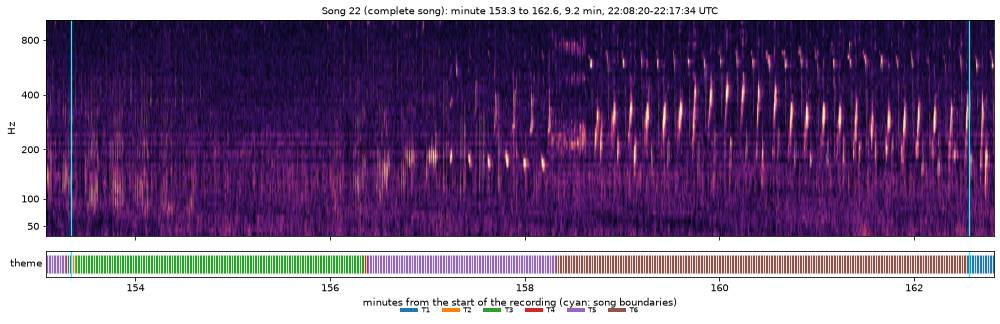

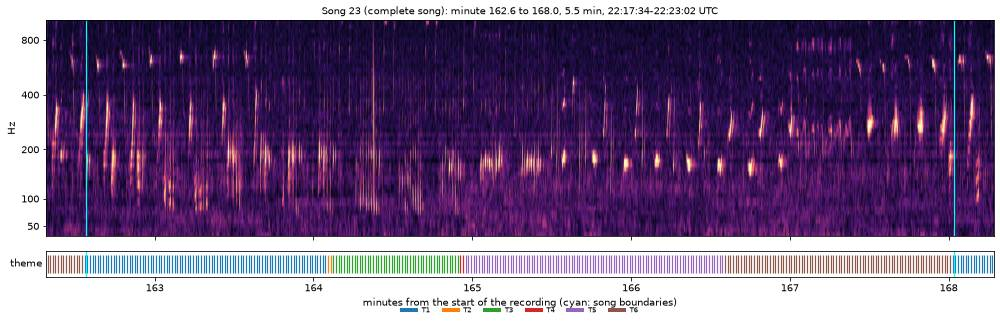

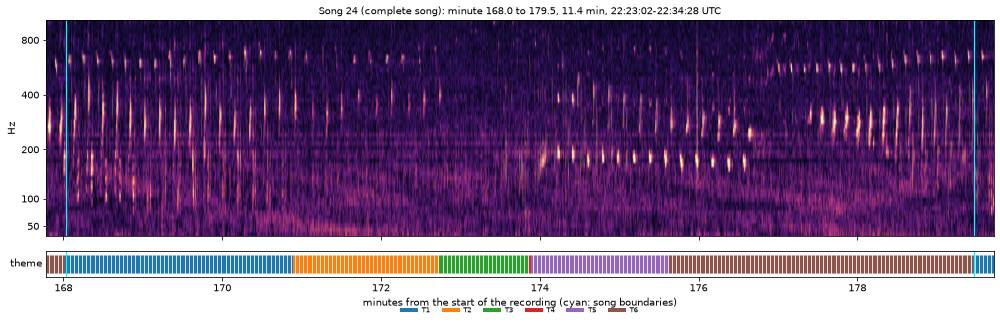

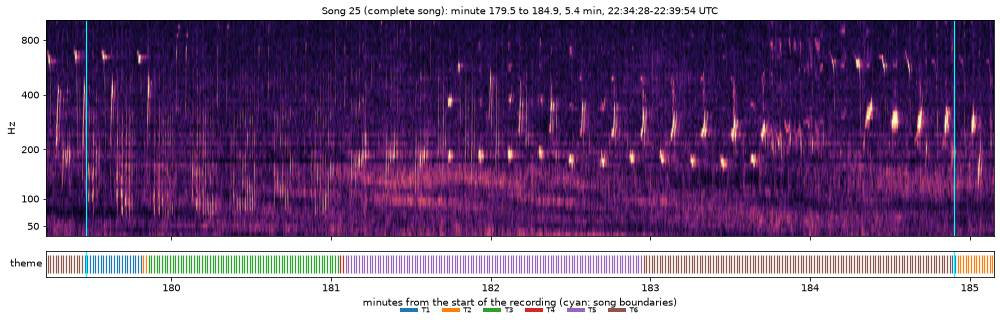

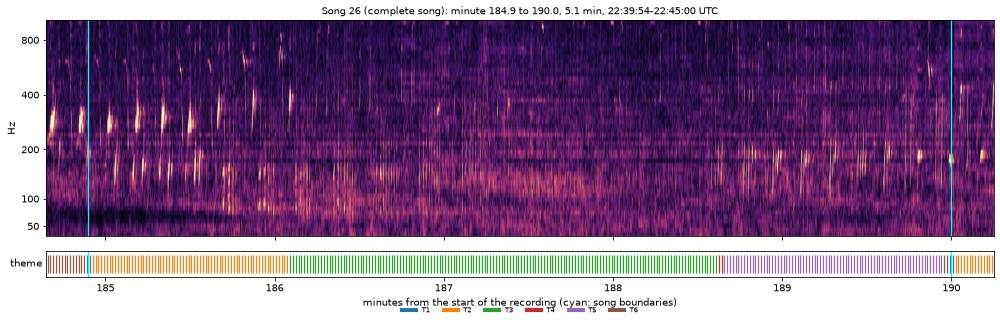

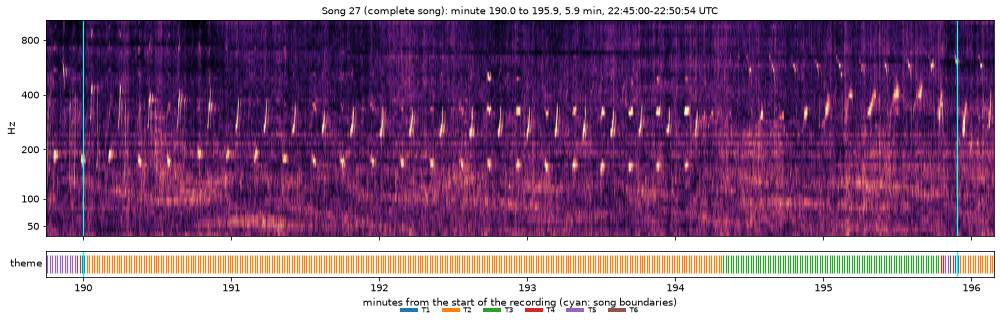

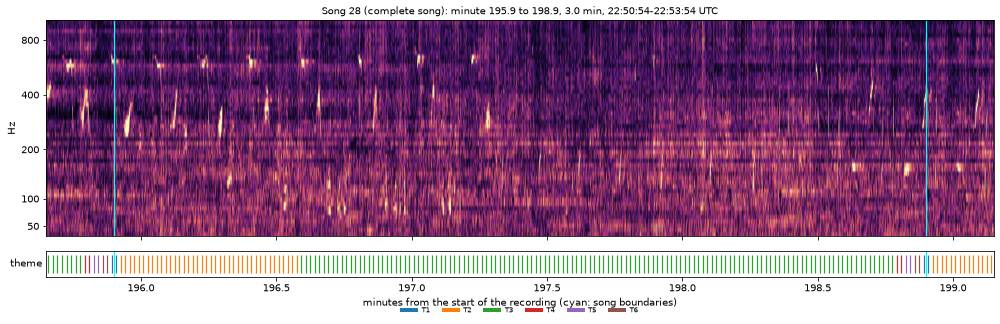

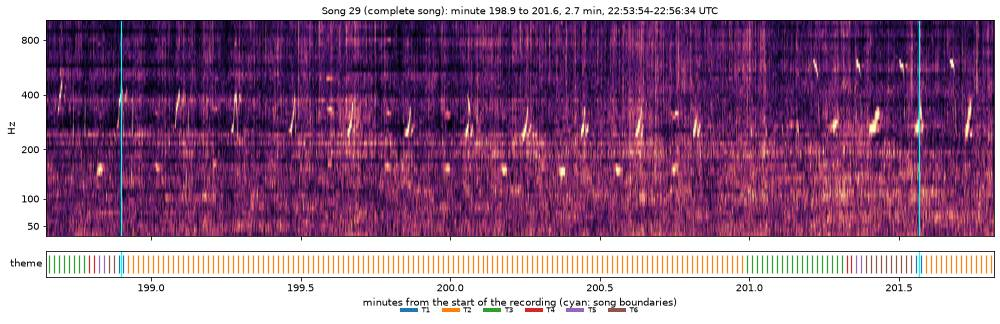

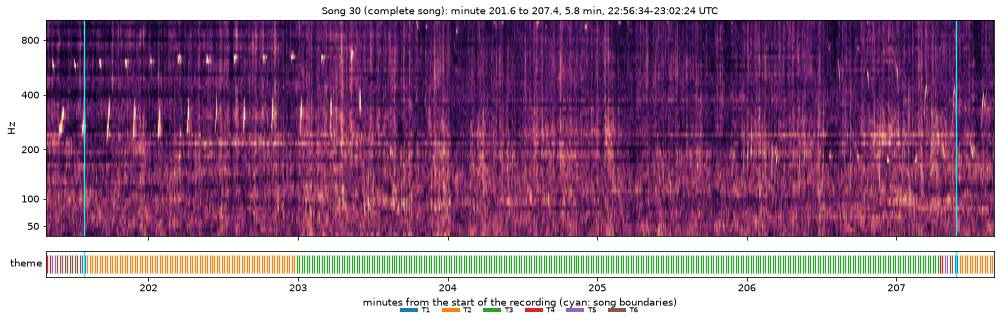

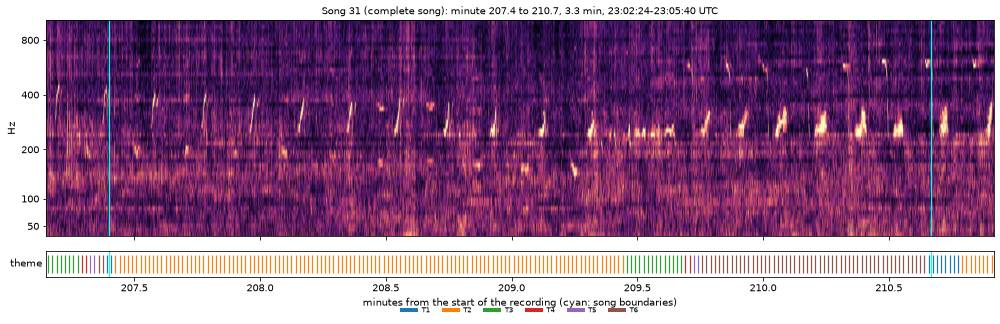

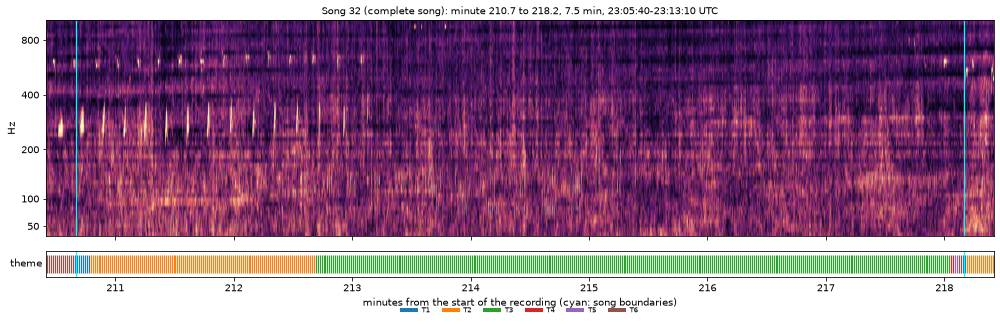

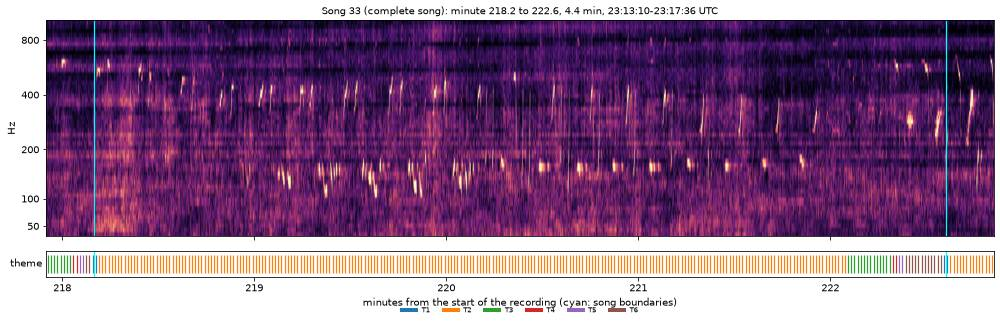

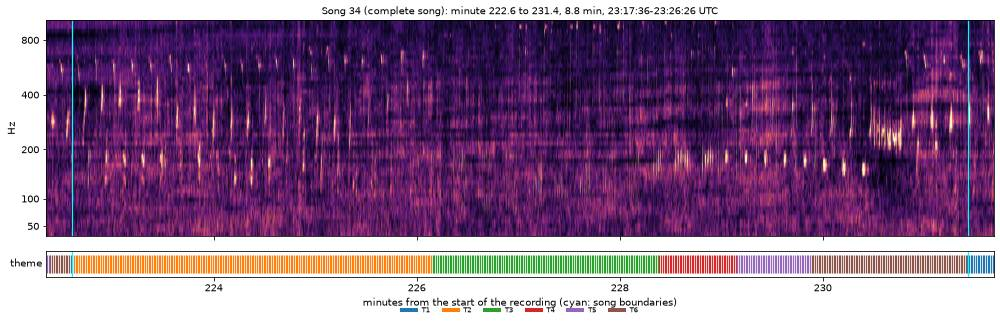

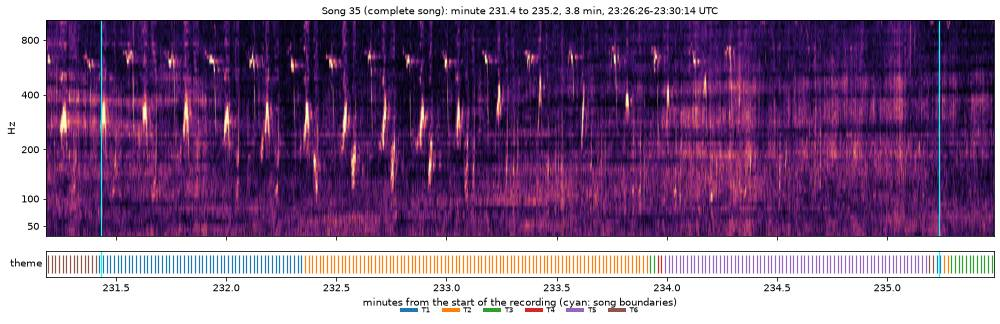

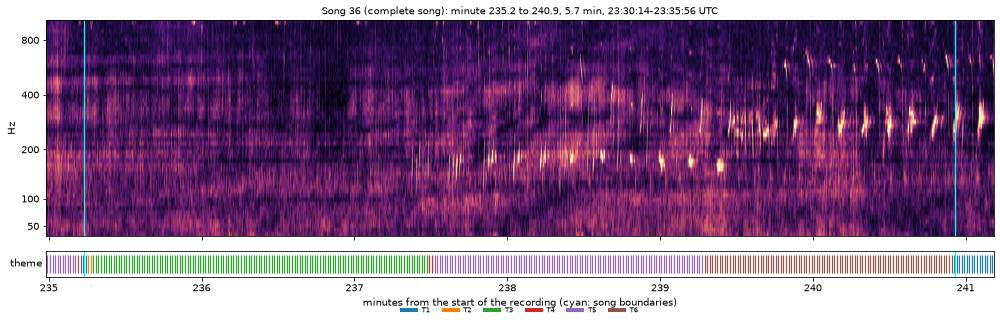

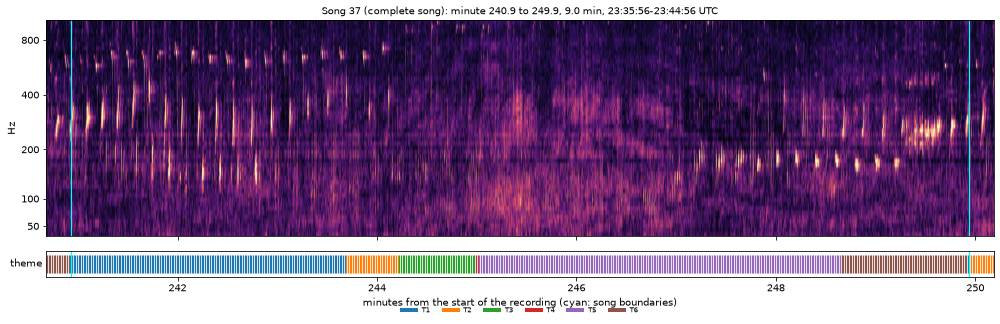

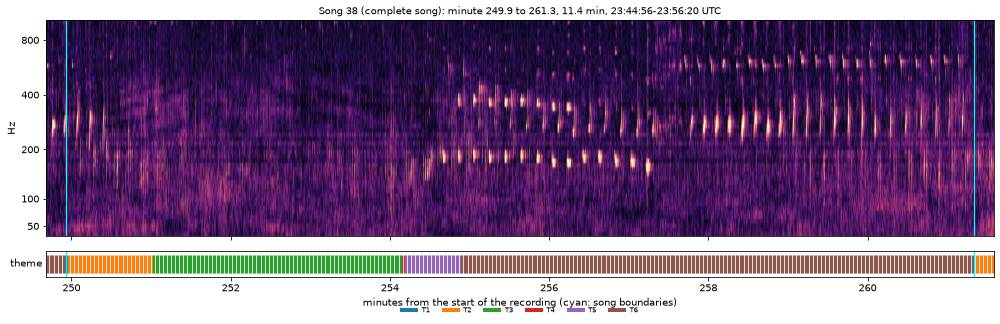

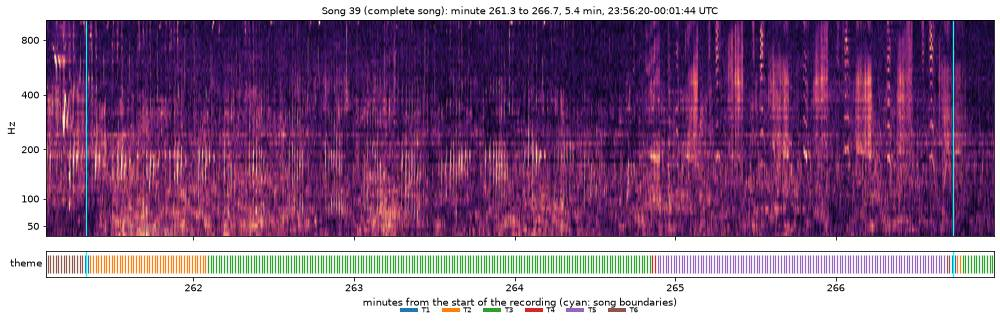

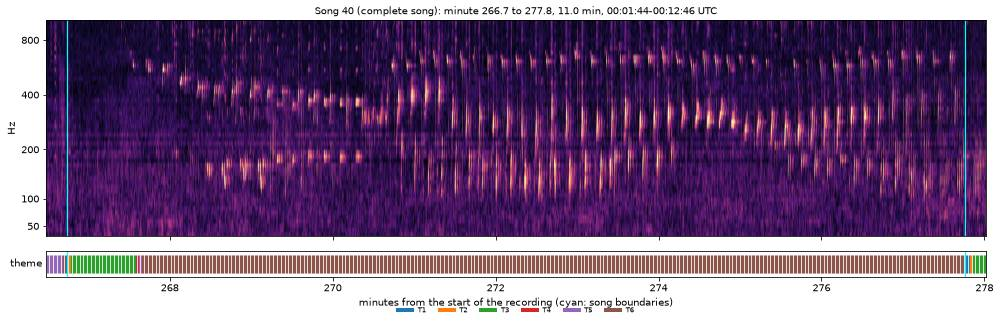

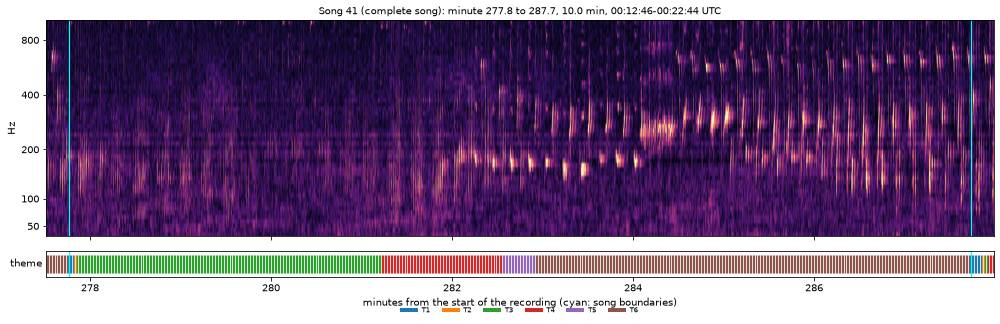

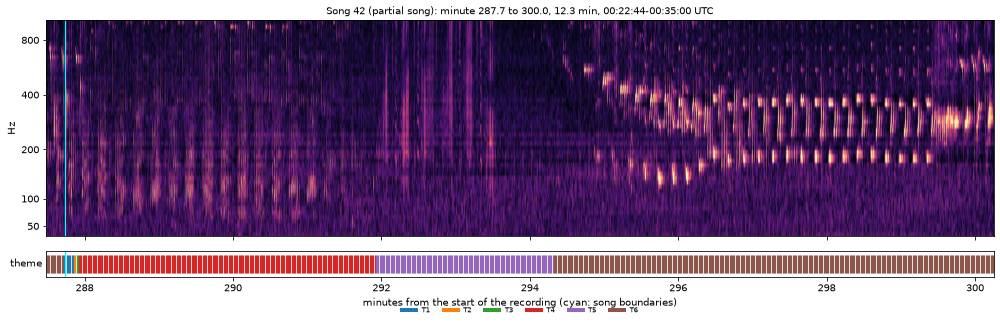

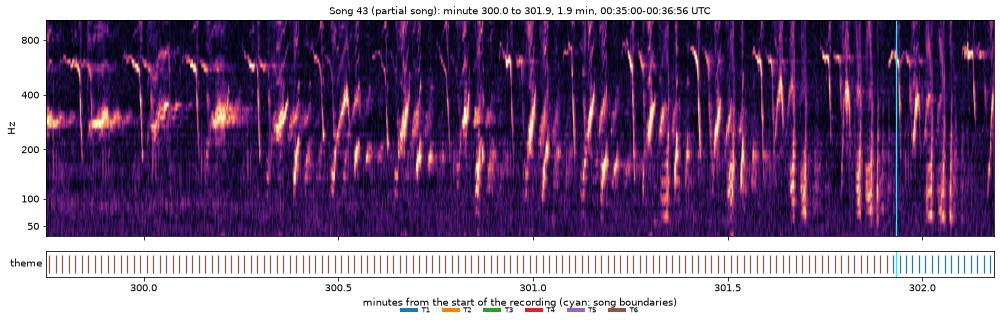

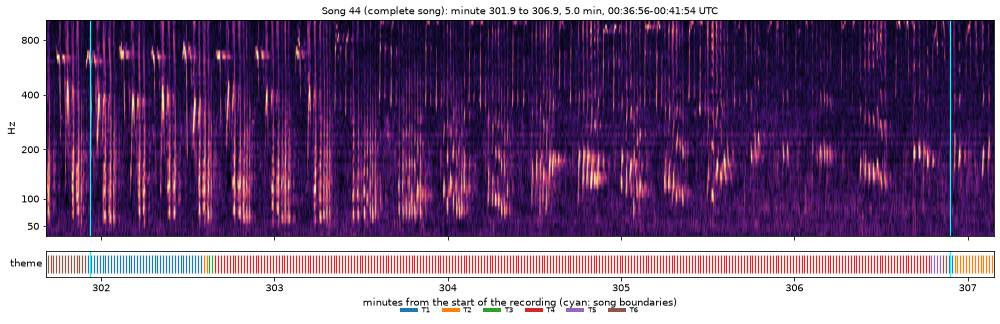

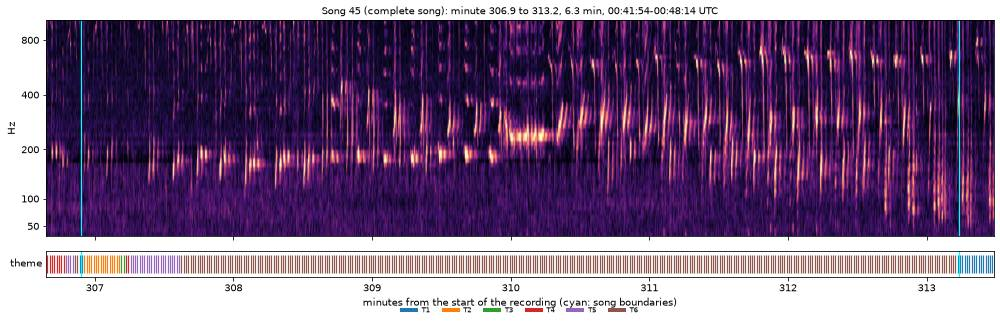

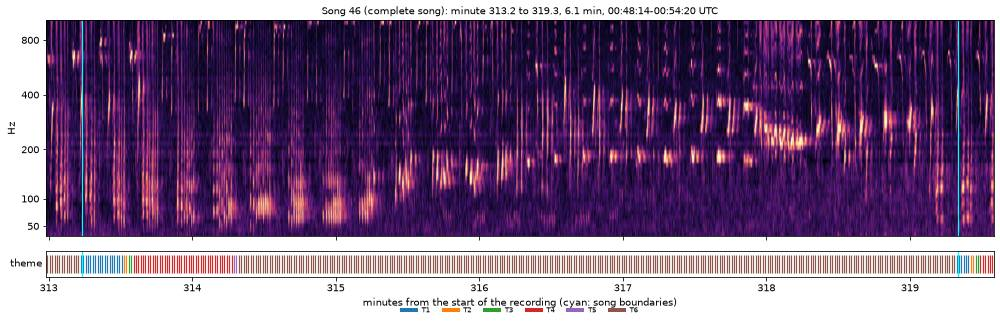

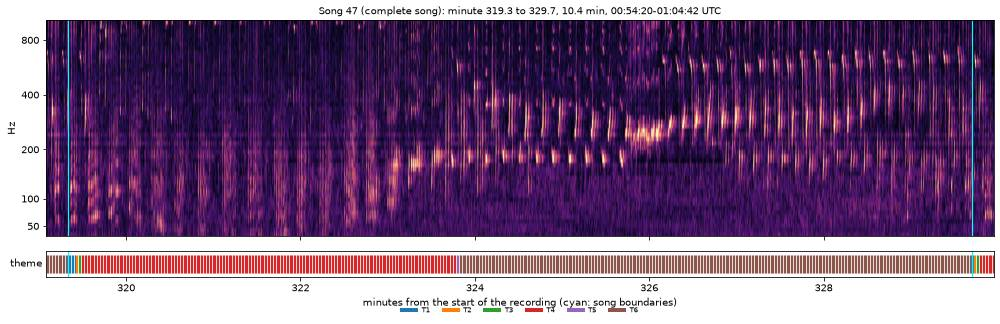

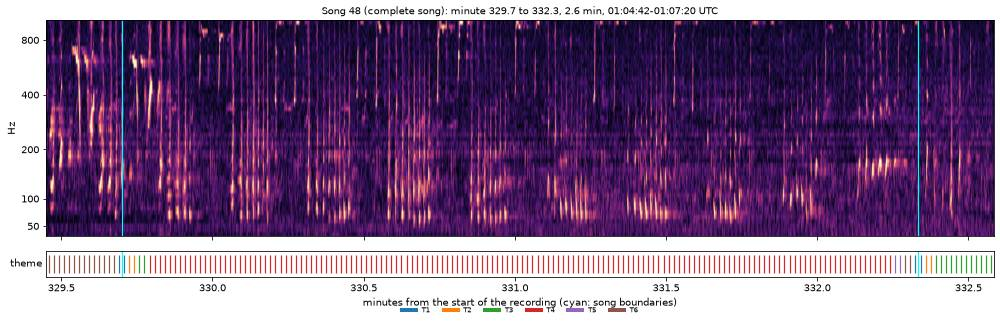

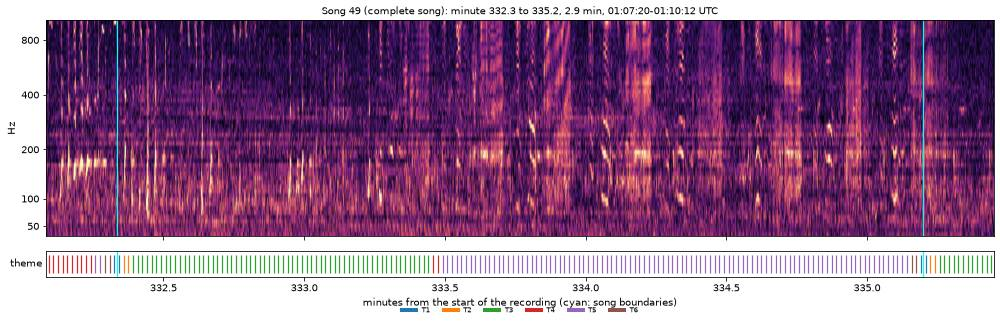

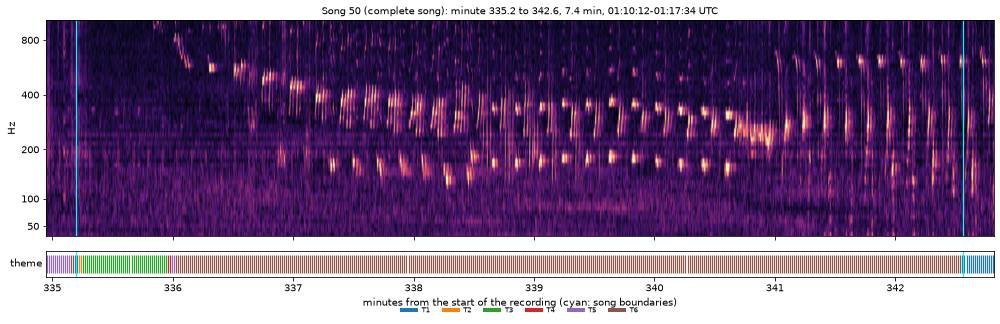

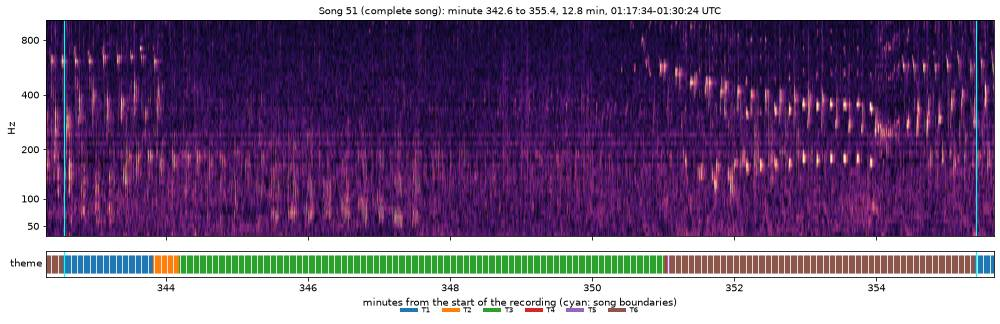

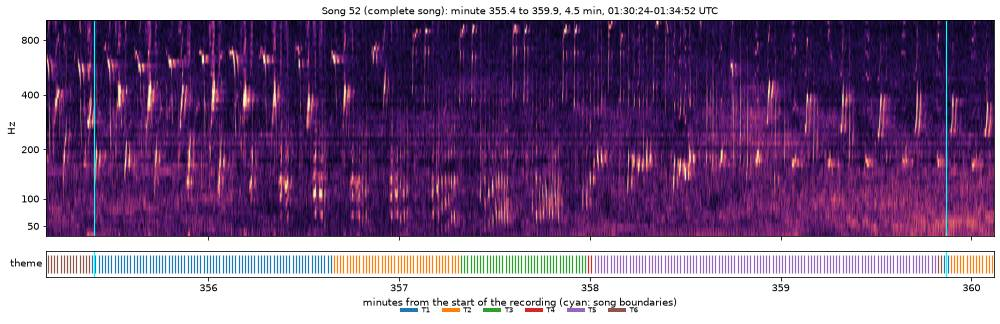

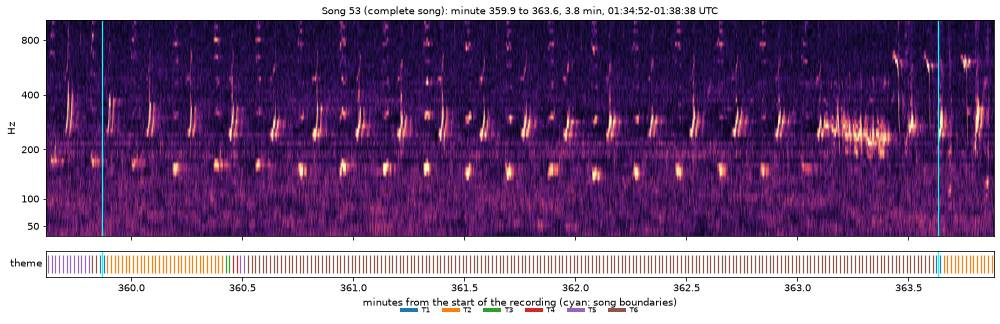

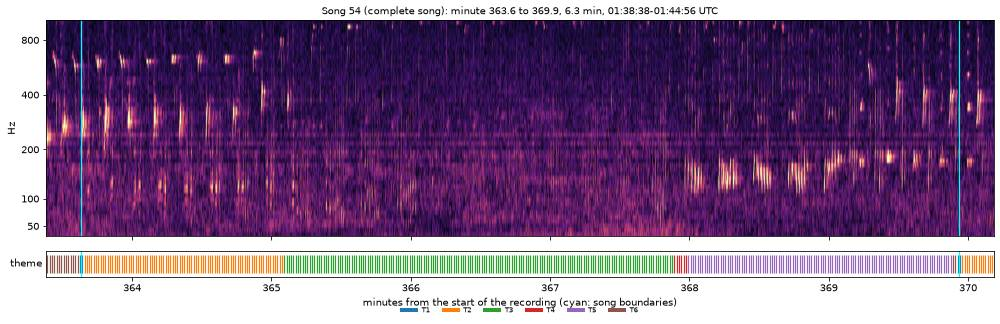

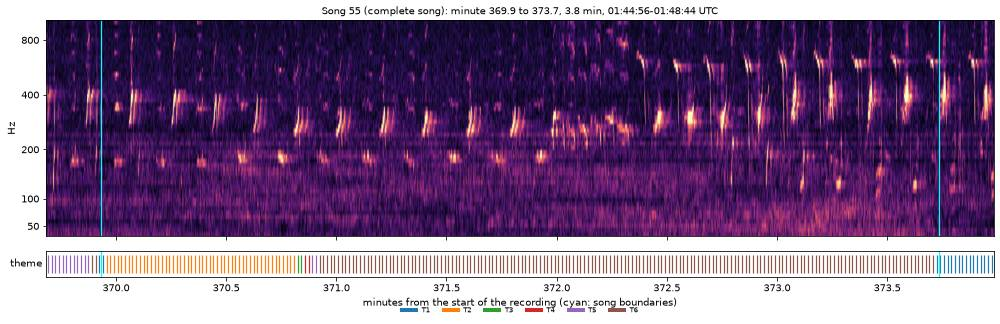

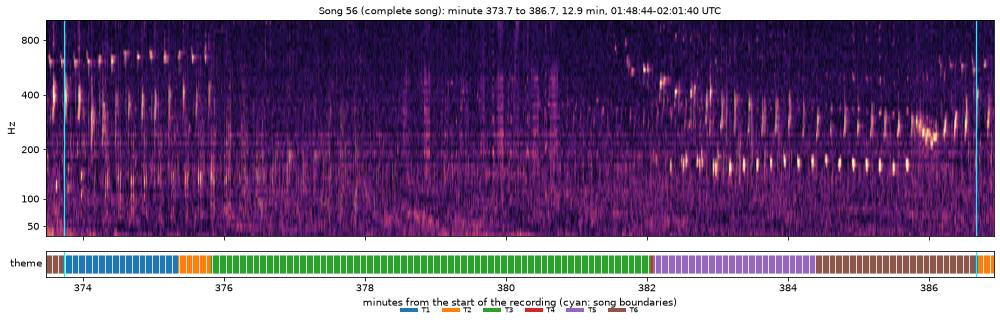

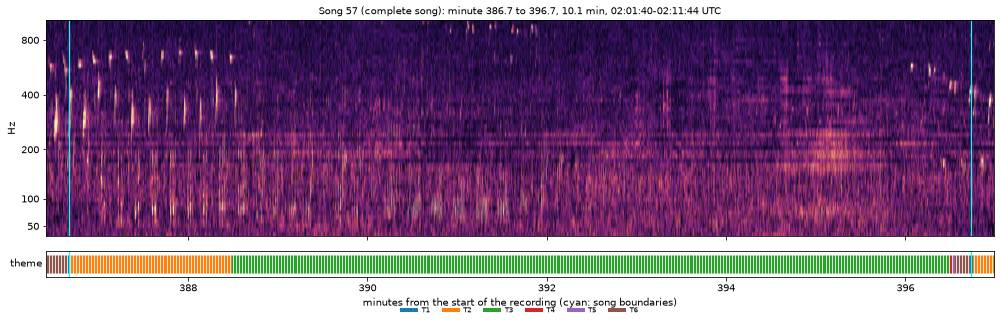

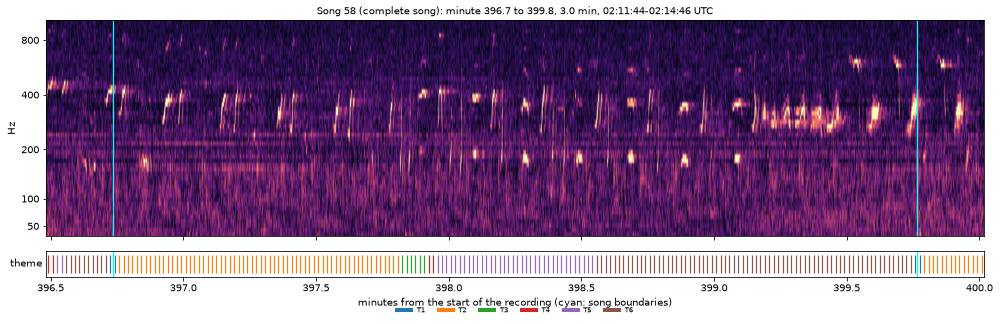

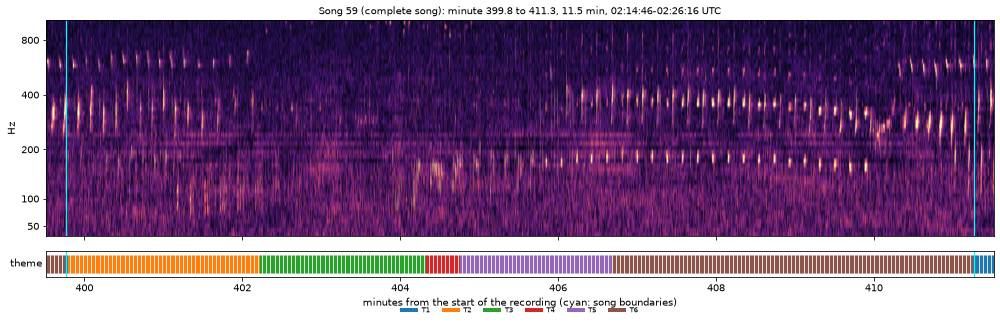

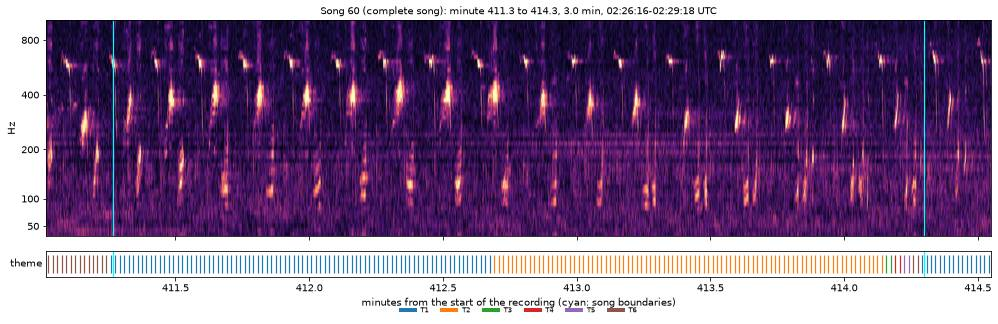

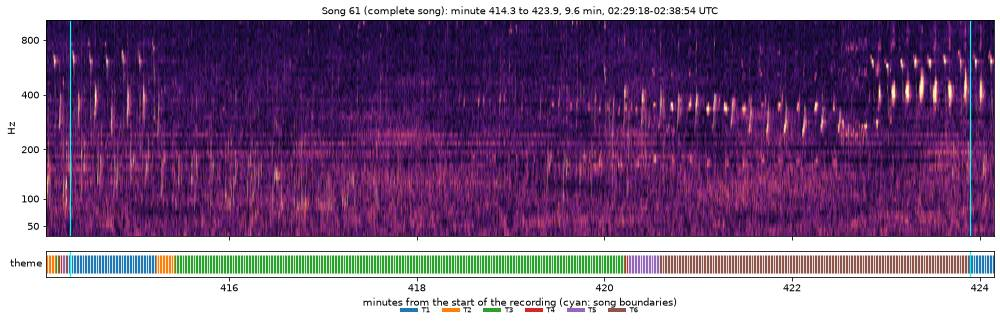

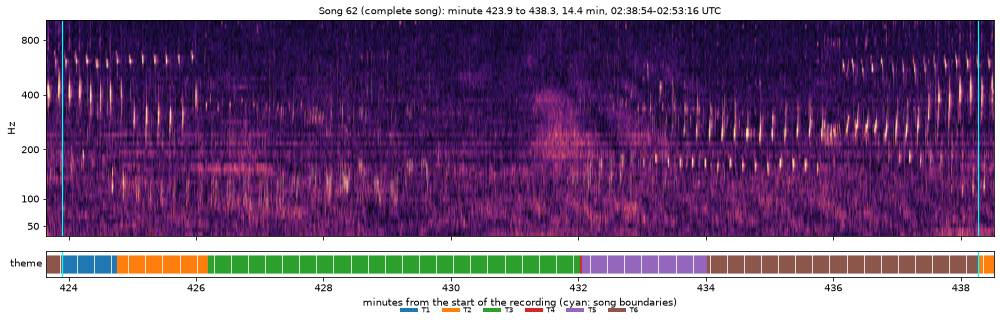

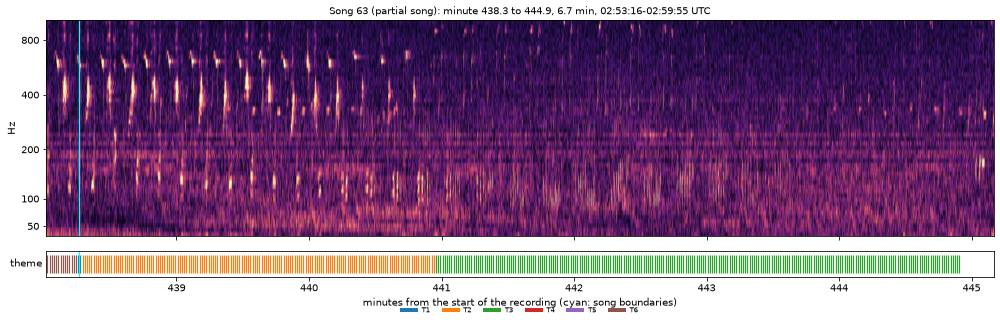

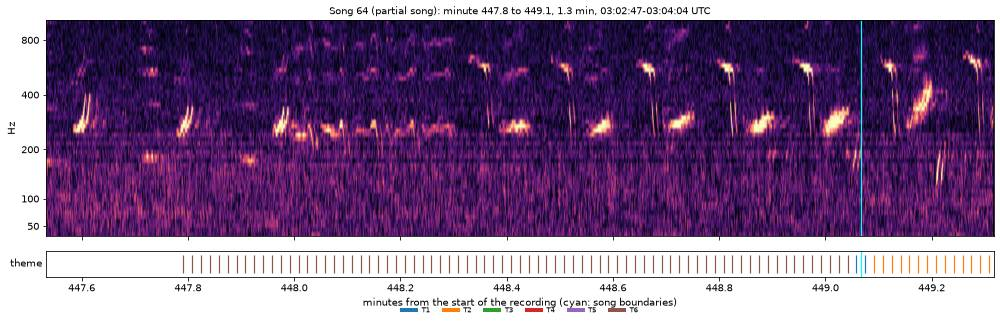

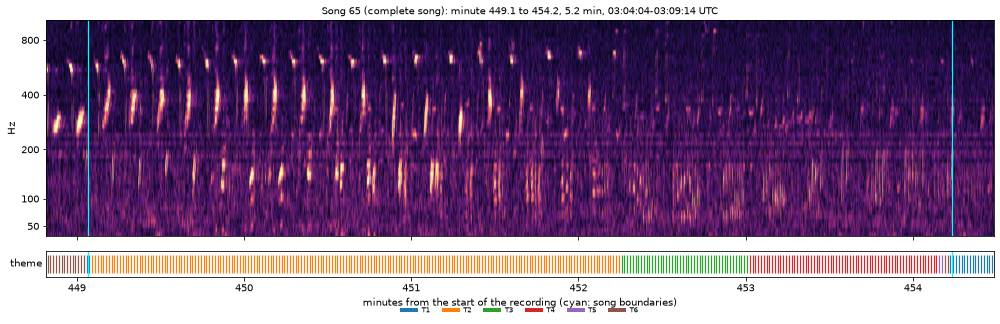

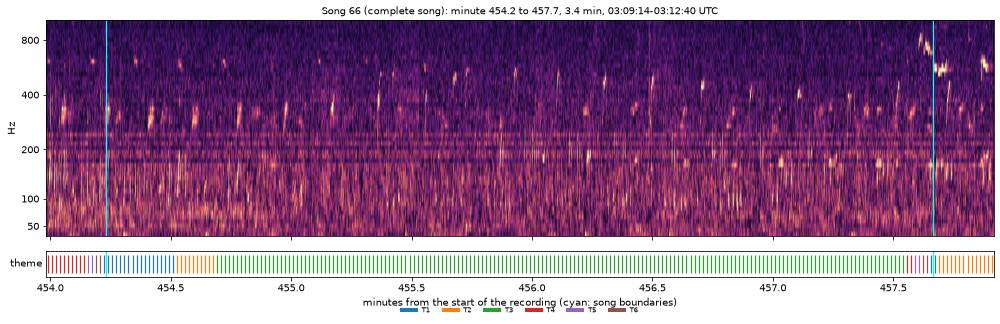

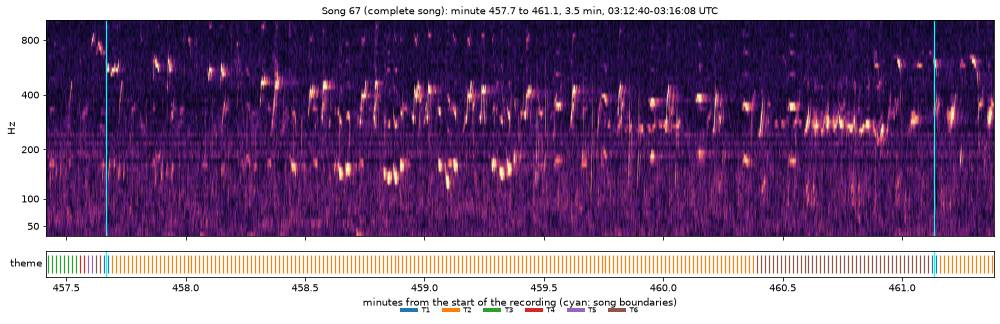

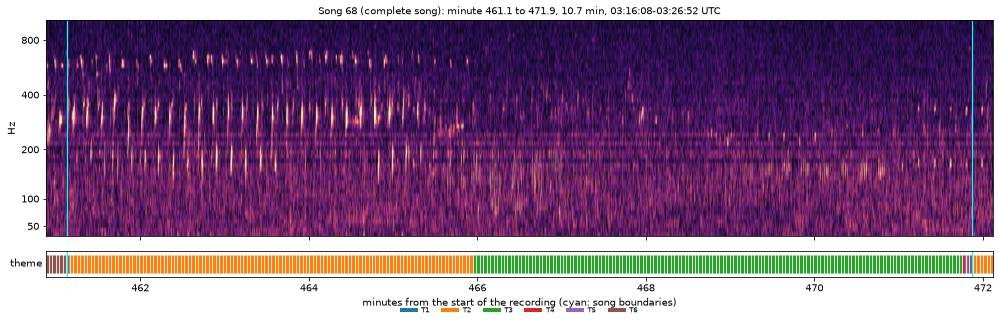

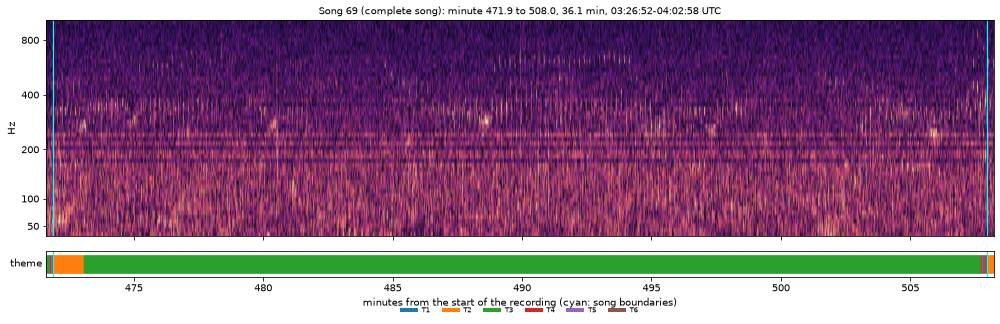

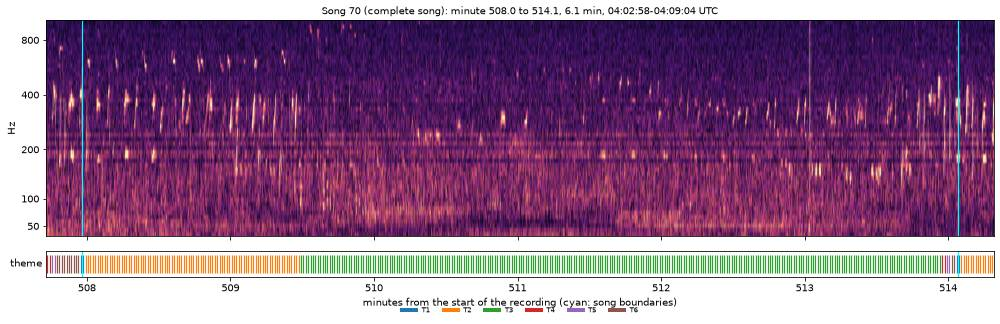

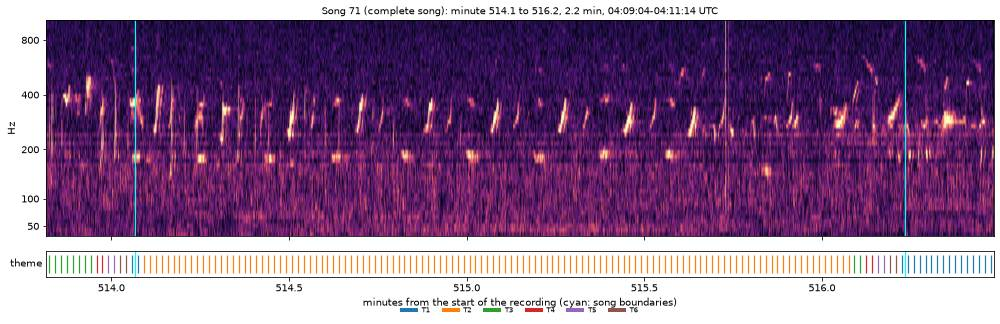

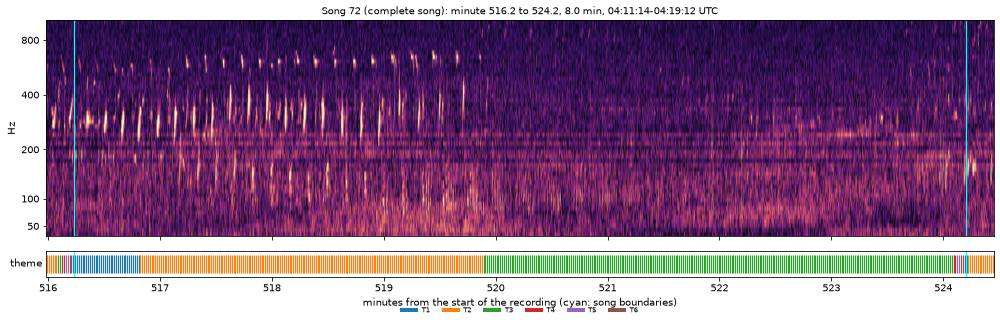

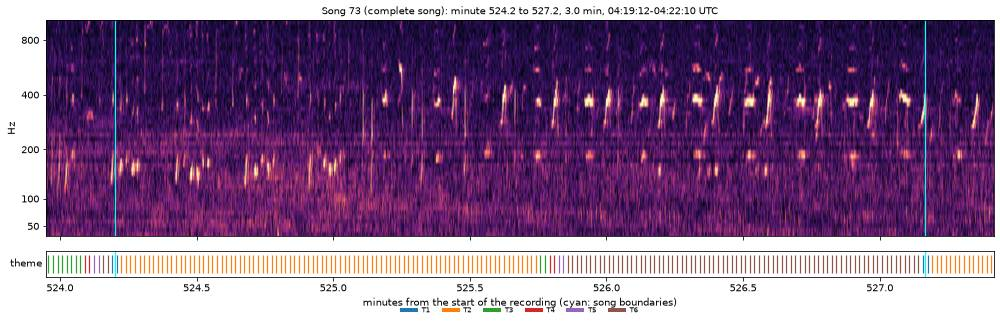

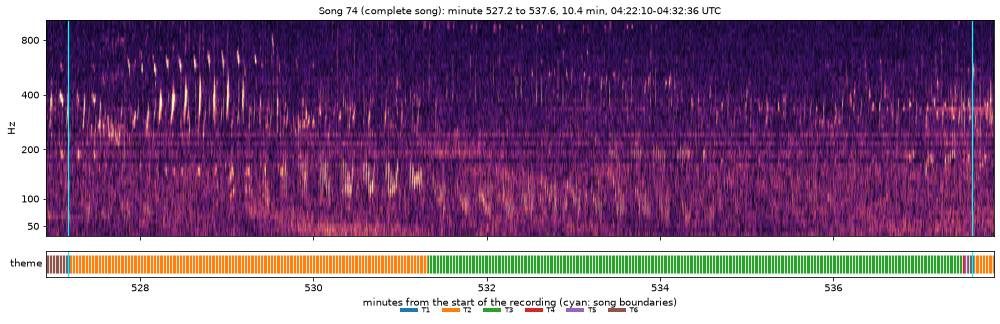

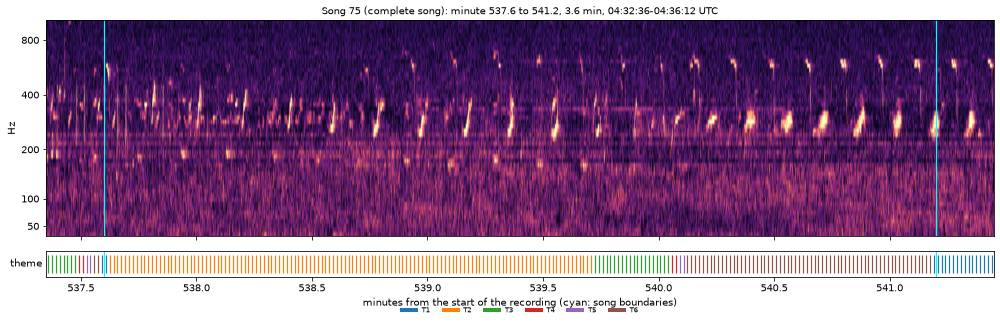

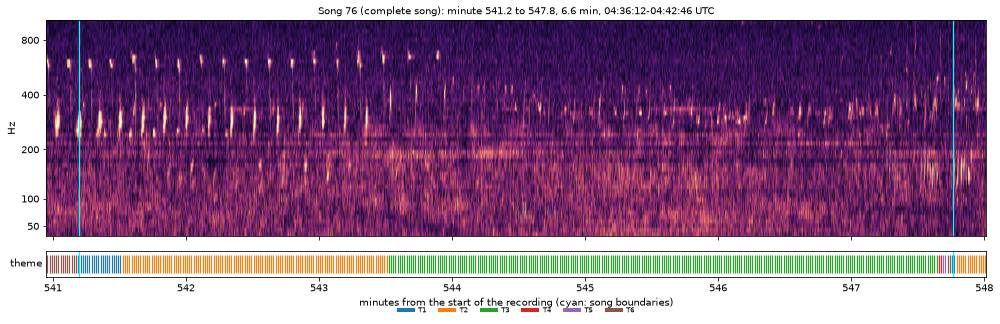

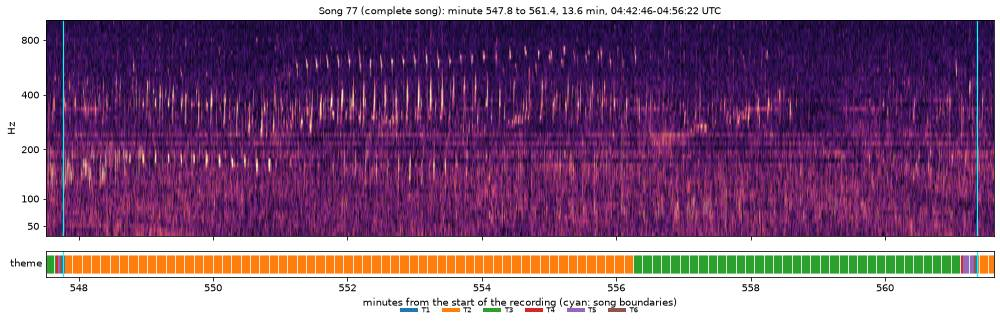

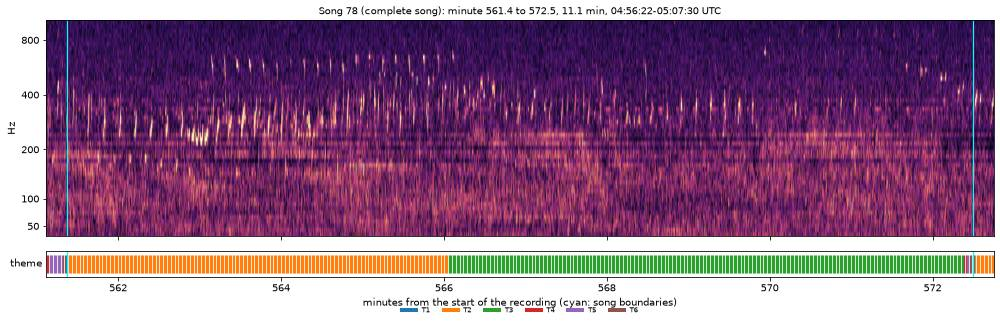

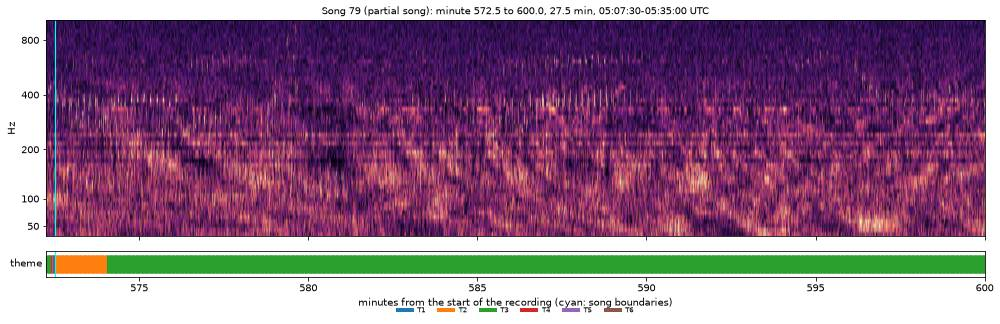

In [5]:
out = detect.WORK / "song_spectrograms"
out.mkdir(parents=True, exist_ok=True)
for song in songs:
    fig = detect.plot_song(song, decoded, save_to=out / f"song_{song.number:02d}.png")
    plt.show()
    plt.close(fig)

## 4. Any stretch you choose

`plot_span(start_s, end_s, decoded)` shows any stretch, given in seconds from the start of the recording. For example, minute 14 to minute 21:

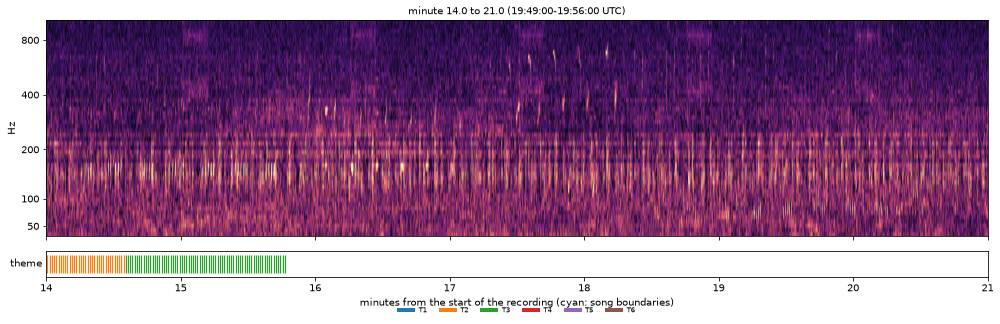

In [6]:
fig = detect.plot_span(14 * 60, 21 * 60, decoded)

To look at one song from the table, pass its number:

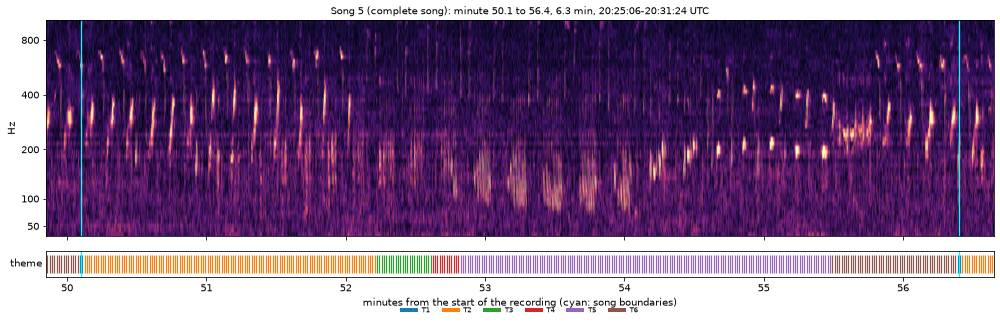

In [7]:
song_number = 5
fig = detect.plot_song(songs[song_number - 1], decoded)